<a href="https://colab.research.google.com/github/Shahd-Ahmed-Eltabii/machine-learning-customer-segmentation/blob/main/ML_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation & Marketing Strategy Recommendation System
**Dataset:** Online Retail (UCI) - real transactions of a UK online retailer, 1 Dec 2010 to 9 Dec 2011. Each row is one product line inside an invoice.

**Project goal:** Segment customers with K-Means on RFM (Recency, Frequency, Monetary), profile each cluster, then build a rule-based system that recommends a marketing strategy per cluster.

## Part 1 – Data Collection & Preprocessing (this notebook section)
1. Load the data
2. Initial exploration
3. Cleaning: missing CustomerID → duplicates → invalid prices → non-product codes
4. Cancelled invoices: diagnose, then separate
5. Feature: `TotalPrice`
6. Final check, cleaning summary, and save

## 1) Load the Data
Import the libraries, download the dataset from UCI (zip), and read it into `df`.
`df` is the raw copy and is never modified. All cleaning happens on `df_clean`.


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile


In [40]:
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
with open("online_retail.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("online_retail.zip", "r") as zip_ref:
    zip_ref.extractall("data")

df = pd.read_excel("data/Online Retail.xlsx")   # raw data - do not modify
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2) Initial Exploration
Check the dataset's dimensions, data types, missing values, and descriptive statistics.

The dataset contains 541,909 rows and 8 columns, as expected.

The initial inspection revealed missing values in two columns:

`CustomerID`: 135,080 missing values.

`Description`: 1,454 missing values.

In [41]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.info()

Number of Rows: 541909
Number of Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [42]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


**Descriptive statistics:** compare the mean with the extreme values to spot outliers and illogical values (negative quantities and prices).

In [43]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [44]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


## 3) Cleaning
We start from a copy, `df_clean`.
remove rows that cannot be used at all first (no customer), then duplicates, then invalid values.
we use a small `log` list to records the row count after every step, and we print it as a summary at the end.

### 3.1) Drop Rows Without CustomerID
**Why:** RFM is computed per customer, so a row with no customer cannot contribute to Recency / Frequency / Monetary.
`CustomerID` is then converted from float to int (it was float only because of the NaNs).
**Result:** 406,829 rows remain.
**Note:** results will describe registered customers only, not total sales.

In [45]:
log = [("Raw data", len(df))]

df_clean = df.dropna(subset=["CustomerID"]).copy()
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

log.append(("Drop missing CustomerID", len(df_clean)))
print(f"Rows before: {len(df):,}")
print(f"Rows after : {len(df_clean):,}")

Rows before: 541,909
Rows after : 406,829


### 3.2) Drop Duplicate Rows
**Why:** a row identical in every column is most likely a duplicate entry, and keeping it inflates the customer's Monetary value.
**Result:** 5,225 duplicate rows removed, leaving 401,604 rows.

In [46]:
print("Duplicated Rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

log.append(("Drop duplicates", len(df_clean)))
print(f"Rows after: {len(df_clean):,}")

Duplicated Rows: 5225
Rows after: 401,604


### 3.3) Drop Zero and Negative Prices
**Why:** a zero or negative price is not a real sale (accounting adjustments or free items) and distorts Monetary.
**Result:** 40 rows removed, leaving **401,564** rows.

In [47]:
before = len(df_clean)
df_clean = df_clean[df_clean["UnitPrice"] > 0].reset_index(drop=True)

log.append(("Drop UnitPrice <= 0", len(df_clean)))
print(f"Removed    : {before - len(df_clean):,}")
print(f"Rows after : {len(df_clean):,}")

Removed    : 40
Rows after : 401,564


### 3.4) Drop Non-Product Codes (Postage, Fees, Adjustments)
**Why:** codes such as `POST` (postage) or `D` (discount) are charges, not products the customer bought. Keeping them would inflate Monetary because of shipping alone, and `M` (manual entries) even has a large negative total.

First we inspect: a regular product code is 5 digits optionally followed by letters (for example `85123A`). Anything else is listed so we can review it before deleting.

In [48]:
is_product = df_clean["StockCode"].astype(str).str.match(r"^\d{5}[A-Za-z]*$")

non_product = df_clean.loc[~is_product].assign(
    LineTotal=lambda d: d["Quantity"] * d["UnitPrice"]
)

summary = (non_product.groupby("StockCode")
           .agg(rows=("StockCode", "size"),
                description=("Description", "first"),
                total_value=("LineTotal", "sum"))
           .sort_values("rows", ascending=False))
display(summary)

,rows,description,total_value
StockCode,,,
POST,1196,POSTAGE,66710.240
M,454,Manual,-58745.460
C2,134,CARRIAGE,6636.000
D,77,Discount,-5696.220
DOT,16,DOTCOM POSTAGE,11906.360
CRUK,16,CRUK Commission,-7933.430
BANK CHARGES,12,Bank Charges,165.001
PADS,3,PADS TO MATCH ALL CUSHIONS,0.003


**Review result:** `POST`, `M`, `C2`, `D`, `DOT`, `CRUK` and `BANK CHARGES` are charges/adjustments and are removed.
`PADS` ("Pads to match all cushions") is a real product with an unusual code (3 rows, almost zero value), so it is kept.
**Result:** 1,905 rows removed (366 of them inside `C` invoices), leaving **399,659** rows.
The removed rows are kept in `df_non_product` .

In [49]:
non_product_codes = {"POST", "M", "C2", "D", "DOT", "CRUK", "BANK CHARGES"}

is_np = df_clean["StockCode"].astype(str).isin(non_product_codes)

df_non_product = df_clean[is_np].copy()          # keep what we remove
df_clean = df_clean[~is_np].reset_index(drop=True)

log.append(("Drop non-product codes", len(df_clean)))
print(f"Removed    : {len(df_non_product):,}")
print(f"Rows after : {len(df_clean):,}")
assert "PADS" in set(df_clean["StockCode"].astype(str))

# How many of the removed rows were inside cancelled invoices?
in_cancel = df_non_product["InvoiceNo"].astype(str).str.startswith("C").sum()
print(f"Of the removed rows, inside 'C' invoices: {in_cancel:,}")   # expected: 366

Removed    : 1,905
Rows after : 399,659
Of the removed rows, inside 'C' invoices: 366


## 4) Cancelled Invoices
Invoices whose `InvoiceNo` starts with `C` are cancellations/returns and have negative quantities.

### 4.1) Diagnose
**What we found:** every negative quantity (8,506 rows) is inside a `C` invoice, and there are none outside.

In [50]:
cancel_mask = df_clean["InvoiceNo"].astype(str).str.strip().str.startswith("C")
neg_qty = df_clean["Quantity"] < 0

print("Cancelled rows            :", f"{cancel_mask.sum():,}")
print("Unique cancelled invoices :", f"{df_clean.loc[cancel_mask, 'InvoiceNo'].nunique():,}")
print("\nNegative quantity rows            :", f"{neg_qty.sum():,}")
print("Negative quantity inside 'C' only :", f"{(neg_qty & cancel_mask).sum():,}")
print("Negative quantity NOT in 'C'      :", f"{(neg_qty & ~cancel_mask).sum():,}")

Cancelled rows            : 8,506
Unique cancelled invoices : 3,383

Negative quantity rows            : 8,506
Negative quantity inside 'C' only : 8,506
Negative quantity NOT in 'C'      : 0


### 4.2) Separate Cancellations
**Decision:** move `C` invoices out of `df_clean` into `df_cancel`.
**Why:** RFM should measure 'buying' behavior. Returns would lower Monetary and could be counted as extra invoices in Frequency. We keep `df_cancel` aside.
**Result:** 8,506 cancelled rows moved to `df_cancel` (the other 366 cancellation rows were non-product codes already removed in 3.4), and no negative quantities are left in `df_clean`.

In [51]:
df_cancel = df_clean[cancel_mask].copy()
df_clean = df_clean[~cancel_mask].reset_index(drop=True)

log.append(("Separate cancelled invoices", len(df_clean)))
print(f"Cancelled rows moved out: {len(df_cancel):,}")
print(f"Rows left in df_clean   : {len(df_clean):,}")

assert (df_clean["Quantity"] > 0).all()
print("Min Quantity:", df_clean["Quantity"].min())

Cancelled rows moved out: 8,506
Rows left in df_clean   : 391,153
Min Quantity: 1


## 5) Feature: TotalPrice
`TotalPrice = Quantity × UnitPrice` is the amount of each line. We will sum it per customer later to get Monetary.
**Note:** the maximum will stay large (wholesale orders). Outliers are handled at the customer level after RFM is built.

In [52]:
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["TotalPrice"].describe()

,TotalPrice
count,391153.000000
mean,22.337110
std,310.931256
min,0.001000
25%,4.950000
50%,11.900000
75%,19.800000
max,168469.600000


## 6) Final Check, Cleaning Summary, and Save


In [53]:
print("Shape            :", df_clean.shape)
print("Missing values   :", df_clean.isnull().sum().sum())
print("Duplicates       :", df_clean.duplicated().sum())
print("Min Quantity     :", df_clean["Quantity"].min())
print("Min UnitPrice    :", df_clean["UnitPrice"].min())
print("Unique customers :", df_clean["CustomerID"].nunique())
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction :", df_clean["InvoiceDate"].max())

Shape            : (391153, 9)
Missing values   : 0
Duplicates       : 0
Min Quantity     : 1
Min UnitPrice    : 0.001
Unique customers : 4334
First transaction: 2010-12-01 08:26:00
Last transaction : 2011-12-09 12:50:00


In [54]:
summary_log = pd.DataFrame(log, columns=["Step", "Rows after step"])
summary_log["Rows removed"] = -summary_log["Rows after step"].diff().fillna(0).astype(int)
summary_log["Rows after step"] = summary_log["Rows after step"].map("{:,}".format)
summary_log

,Step,Rows after step,Rows removed
0,Raw data,"541,909",0
1,Drop missing CustomerID,"406,829",135080
2,Drop duplicates,"401,604",5225
3,Drop UnitPrice <= 0,"401,564",40
4,Drop non-product codes,"399,659",1905
5,Separate cancelled invoices,"391,153",8506


In [55]:
df_clean.to_csv("clean_retail.csv", index=False)
df_cancel.to_csv("cancelled_retail.csv", index=False)
df_non_product.to_csv("non_product_rows.csv", index=False)

### Part 1 Result

We will continue working with `df_clean`, which contains **391,153 rows** from **4,334 unique customers**, with no missing values or duplicate rows, and only positive quantities and prices.

Cancelled invoices (`df_cancel`) and non-product rows (`df_non_product`) have been kept separately for reference.

##Part 2 – EDA & Data Visualization
Sales by month and country, top products, and the distributions of Recency, Frequency, and Monetary, then RFM feature engineering and scaling.

Number of Transactions.

In [56]:
Number_of_Transactions=len(df_clean)
print(f"Number of Transactions: {Number_of_Transactions}")

Number of Transactions: 391153


Number of Unique Customers.

In [57]:
Number_of_Unique_Customers=df_clean['CustomerID'].nunique()
print(f"Number of Unique Customers: {Number_of_Unique_Customers}")

Number of Unique Customers: 4334


Number of Unique Products.

In [58]:
Number_of_Unique_Products=df_clean['StockCode'].nunique()
print(f"Number of unique products : {Number_of_Unique_Products}")

Number of unique products : 3660


Number of Unique Countries

In [59]:
Number_of_Unique_Countries=df_clean['Country'].nunique()
print(f"Number of unique countries : {Number_of_Unique_Countries}")

Number of unique countries : 37


Date Range.

In [60]:
from_data=df_clean['InvoiceDate'].min()
to_data=df_clean['InvoiceDate'].max()
print(f"data range from {from_data} to {to_data}")

data range from 2010-12-01 08:26:00 to 2011-12-09 12:50:00


Total Revenue.

In [61]:
Total_Revenue=df_clean['TotalPrice'].sum()
print(f"Total Revenue : {Total_Revenue}")

Total Revenue : 8737227.643


Total Quantity Sold.


In [62]:
Total_Quantity_Sold=df_clean['Quantity'].sum()
print(f"Total Quantity sold :{Total_Quantity_Sold}")


Total Quantity sold :5141787


Average Order Value (AOV).


In [63]:
AOV=df_clean['TotalPrice'].sum() / df_clean['InvoiceNo'].nunique()
print(f"AOV {AOV}")


AOV 474.7977199760895


Number of Invoices

In [64]:
Number_of_Invoices=df_clean['InvoiceNo'].nunique()
print(f"Number of Invoices : {Number_of_Invoices}")

Number of Invoices : 18402


Time-Based Analysis

/tmp/ipykernel_996/1469205899.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_sales.index, y=daily_sales.values, ax=axes[1, 0], palette='viridis')


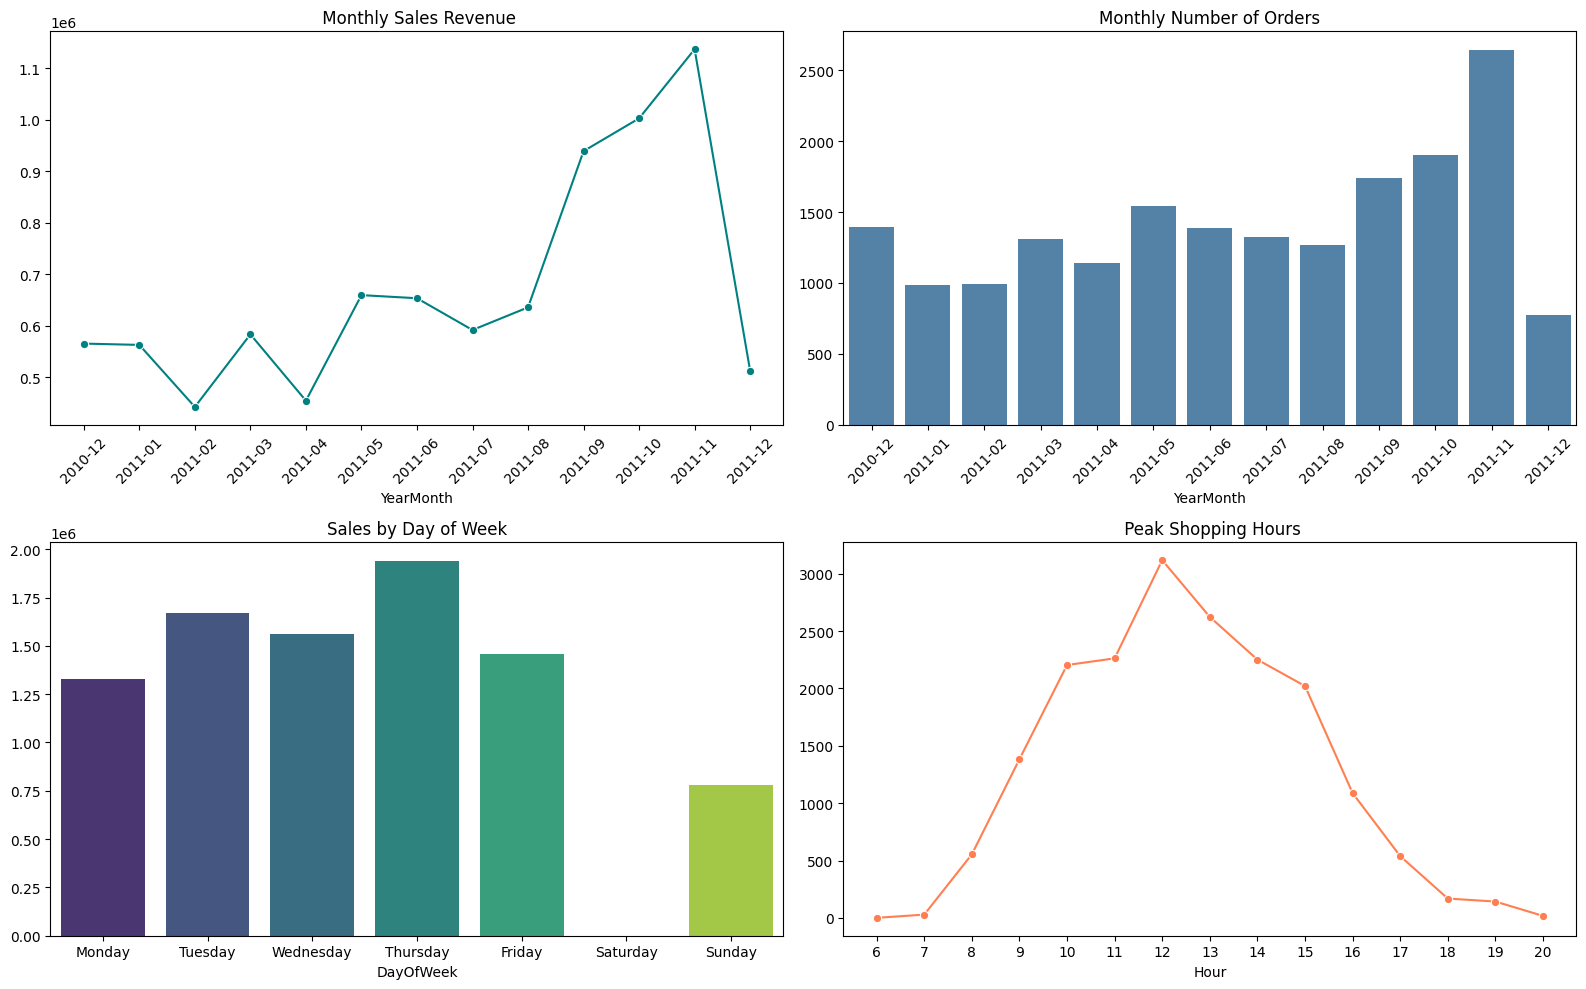

In [65]:
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly Sales Analysis
monthly_sales = df_clean.groupby('YearMonth')['TotalPrice'].sum()
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', ax=axes[0, 0], color='teal')
axes[0, 0].set_title(' Monthly Sales Revenue')
axes[0, 0].tick_params(axis='x', rotation=45)

# Monthly Orders Analysis
monthly_orders = df_clean.groupby('YearMonth')['InvoiceNo'].nunique()
sns.barplot(x=monthly_orders.index, y=monthly_orders.values, ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Monthly Number of Orders')
axes[0, 1].tick_params(axis='x', rotation=45)

#  Daily Sales Trends
daily_sales = df_clean.groupby('DayOfWeek')['TotalPrice'].sum().reindex(days_order).fillna(0)
sns.barplot(x=daily_sales.index, y=daily_sales.values, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Sales by Day of Week')

#  Peak Shopping Periods (Hourly)
hourly_orders = df_clean.groupby('Hour')['InvoiceNo'].nunique()
sns.lineplot(x=hourly_orders.index, y=hourly_orders.values, marker='o', ax=axes[1, 1], color='coral')
axes[1, 1].set_title(' Peak Shopping Hours')
axes[1, 1].set_xticks(range(6, 21))

plt.tight_layout()
plt.show()

Product Analysis

/tmp/ipykernel_996/2075550432.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_qty_products.values, y=top_qty_products.index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_996/2075550432.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rev_products.values, y=top_rev_products.index, ax=axes[1], palette='Greens_r')


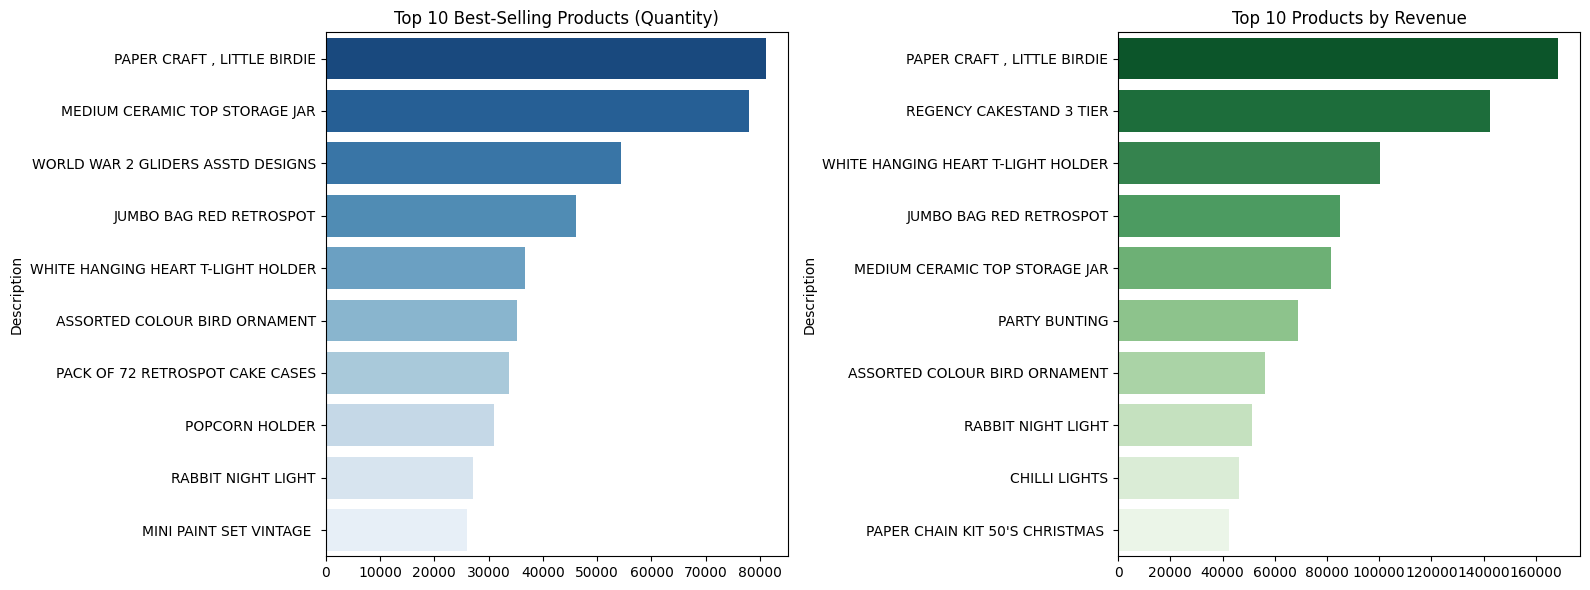

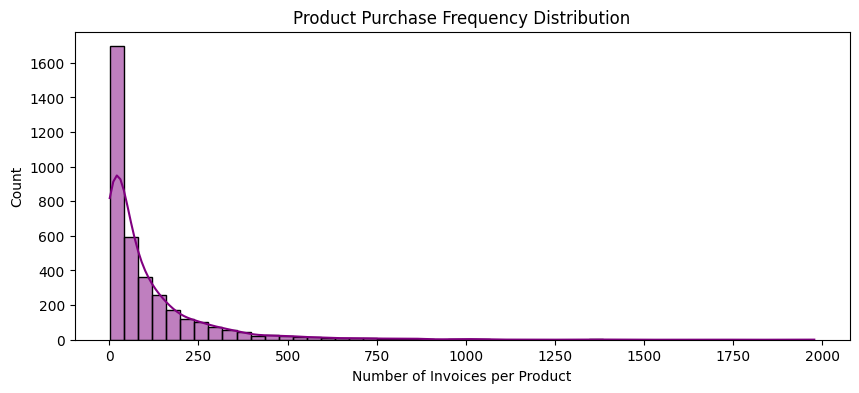

In [66]:
# Top 10 Best-Selling Products (by Quantity)
top_qty_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

# Top 10 Products with Highest Revenue
top_rev_products = df_clean.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top_qty_products.values, y=top_qty_products.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Best-Selling Products (Quantity)')

sns.barplot(x=top_rev_products.values, y=top_rev_products.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 10 Products by Revenue')

plt.tight_layout()
plt.show()

# Product Purchase Distribution
product_dist = df_clean.groupby('StockCode')['InvoiceNo'].nunique()
plt.figure(figsize=(10, 4))
sns.histplot(product_dist, bins=50, kde=True, color='purple')
plt.title('Product Purchase Frequency Distribution')
plt.xlabel('Number of Invoices per Product')
plt.show()

 Country Analysis

Top 10 Countries by Revenue & Customers:
                Unique_Customers  Total_Revenue
Country                                        
United Kingdom              3916    7242855.323
Netherlands                    9     283889.340
EIRE                           3     257013.120
Germany                       94     205381.150
France                        87     183801.940
Australia                      9     138103.810
Spain                         30      55706.560
Switzerland                   21      52441.950
Japan                          8      37416.370
Belgium                       25      36927.340


/tmp/ipykernel_996/338031295.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_countries['Total_Revenue'], y=top_10_countries.index, palette='magma')


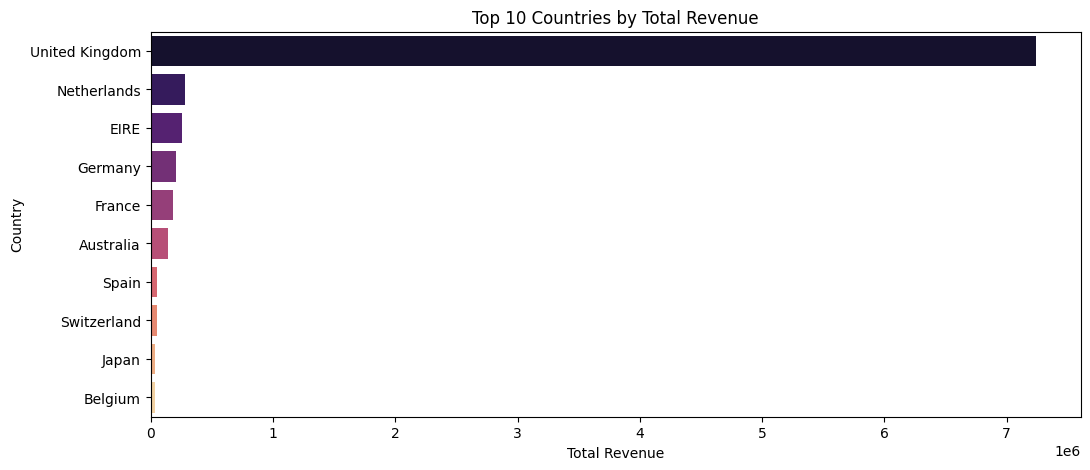

In [67]:
# Number of Customers & Revenue per Country
country_stats = df_clean.groupby('Country').agg(
    Unique_Customers=('CustomerID', 'nunique'),
    Total_Revenue=('TotalPrice', 'sum')
).sort_values(by='Total_Revenue', ascending=False)

print("Top 10 Countries by Revenue & Customers:")
print(country_stats.head(10))

# Top 10 Countries by Revenue Chart
top_10_countries = country_stats.head(10)
plt.figure(figsize=(12, 5))
sns.barplot(x=top_10_countries['Total_Revenue'], y=top_10_countries.index, palette='magma')
plt.title('Top 10 Countries by Total Revenue')
plt.xlabel('Total Revenue')
plt.show()

Customer Behavior Analysis

Average Spending per Customer: 2015.97
Median Spending per Customer: 662.57


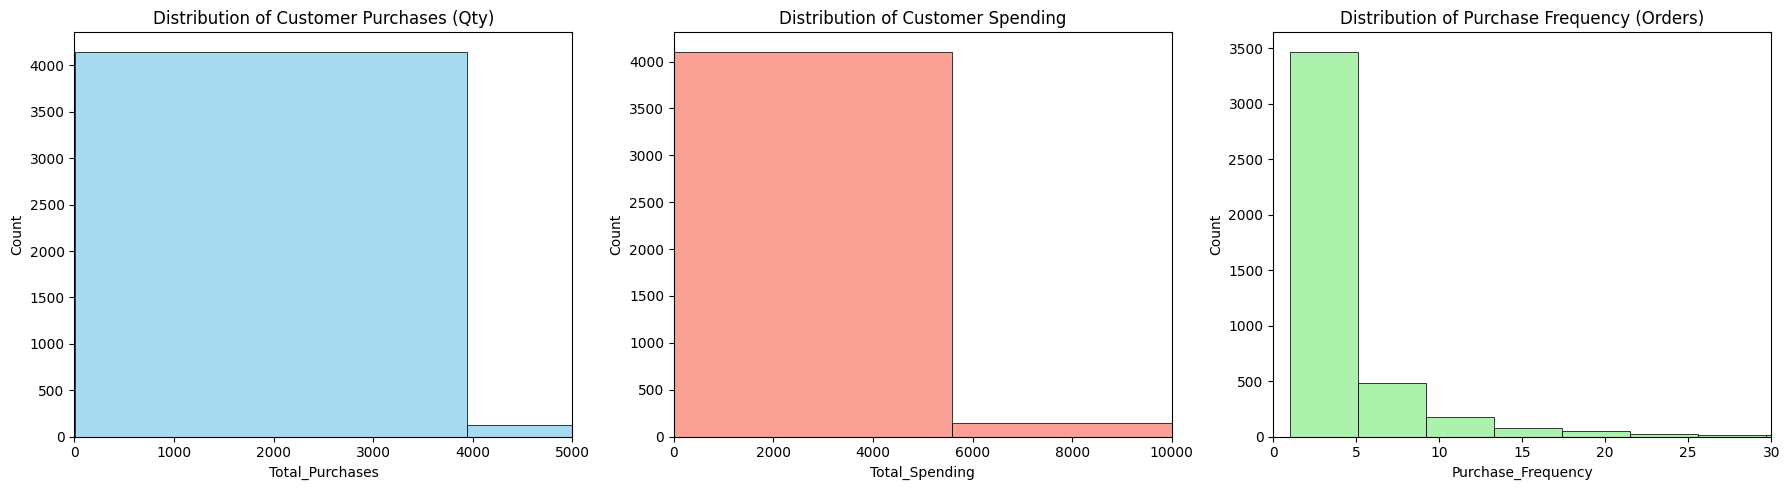

In [68]:
customer_behavior = df_clean.groupby('CustomerID').agg(
    Total_Purchases=('Quantity', 'sum'),
    Total_Spending=('TotalPrice', 'sum'),
    Purchase_Frequency=('InvoiceNo', 'nunique')
)

print("Average Spending per Customer:", round(customer_behavior['Total_Spending'].mean(), 2))
print("Median Spending per Customer:", round(customer_behavior['Total_Spending'].median(), 2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of Customer Purchases
sns.histplot(customer_behavior['Total_Purchases'], bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Customer Purchases (Qty)')
axes[0].set_xlim(0, 5000)

# Distribution of Customer Spending
sns.histplot(customer_behavior['Total_Spending'], bins=50, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Customer Spending')
axes[1].set_xlim(0, 10000)

# Distribution of Purchase Frequency
sns.histplot(customer_behavior['Purchase_Frequency'], bins=50, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Purchase Frequency (Orders)')
axes[2].set_xlim(0, 30)

plt.tight_layout()
plt.show()